# 01 — EDA: Credit Card Fraud Detection (ULB)

`Class`: 0 = bình thường, 1 = gian lận. Chỉ đọc dữ liệu gốc.

## 1. Thư viện

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [2]:
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

CLASS_PALETTE = {0: "#2878B5", 1: "#D9534F"}

## 2. Đọc dữ liệu

In [3]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "creditcard.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy dataset: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
if df.empty:
    raise ValueError("Dataset không có giao dịch để phân tích.")

## 3. Năm dòng đầu

In [5]:
display(df.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 4. Kích thước và kiểu dữ liệu

In [6]:
n_rows, n_columns = df.shape
print(f"Số giao dịch: {n_rows:,}")
print(f"Số cột: {n_columns}")

Số giao dịch: 284,807
Số cột: 31


In [7]:
display(df.dtypes.rename("Kiểu dữ liệu").to_frame())

,Kiểu dữ liệu
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


In [8]:
expected_columns = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]
missing_columns = [column for column in expected_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset thiếu các cột: {missing_columns}")

non_numeric_columns = df[expected_columns].select_dtypes(exclude="number").columns.tolist()
if non_numeric_columns:
    raise ValueError(f"Cần kiểm tra lại kiểu dữ liệu của các cột: {non_numeric_columns}")
if not df["Class"].dropna().isin([0, 1]).all():
    raise ValueError("Cột Class có giá trị khác 0 và 1; hãy kiểm tra dataset.")
print("Các cột cần thiết có mặt và có kiểu số; nhãn hợp lệ là 0 và 1.")

Các cột cần thiết có mặt và có kiểu số; nhãn hợp lệ là 0 và 1.


## 5. Dữ liệu thiếu

In [9]:
missing_table = pd.DataFrame({
    "Số giá trị thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": df.isna().mean() * 100,
}).sort_values("Số giá trị thiếu", ascending=False)

display(missing_table)
total_missing = int(df.isna().sum().sum())
print(f"Tổng số ô bị thiếu: {total_missing:,}")

,Số giá trị thiếu,Tỷ lệ thiếu (%)
Time,0,0.0000
V1,0,0.0000
V2,0,0.0000
V3,0,0.0000
V4,0,0.0000
V5,0,0.0000
V6,0,0.0000
V7,0,0.0000
V8,0,0.0000
V9,0,0.0000


Tổng số ô bị thiếu: 0


## 6. Dữ liệu trùng lặp

Đếm các bản sao sau lần xuất hiện đầu; giữ nguyên các dòng trùng trong EDA.

In [10]:
duplicate_mask = df.duplicated()
n_duplicates = int(duplicate_mask.sum())
n_rows_in_duplicate_groups = int(df.duplicated(keep=False).sum())

print(f"Số dòng trùng sau lần xuất hiện đầu: {n_duplicates:,}")
print(f"Tỷ lệ dòng trùng: {n_duplicates / n_rows * 100:.4f}%")
print(f"Tổng số dòng thuộc các nhóm trùng: {n_rows_in_duplicate_groups:,}")
print("Một số dòng trùng (nếu có):")
display(df.loc[duplicate_mask].head())

Số dòng trùng sau lần xuất hiện đầu: 1,081
Tỷ lệ dòng trùng: 0.3796%
Tổng số dòng thuộc các nhóm trùng: 1,854
Một số dòng trùng (nếu có):


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0000,-0.5299,0.8739,1.3472,0.1455,0.4142,0.1002,0.7112,0.1761,-0.2867,-0.4847,0.8725,0.8516,-0.5717,0.1010,-1.5198,-0.2844,-0.3105,-0.4042,-0.8234,-0.2903,0.0469,0.2081,-0.1855,0.0010,0.0988,-0.5529,-0.0733,0.0233,6.1400,0
35,26.0000,-0.5354,0.8653,1.3511,0.1476,0.4337,0.0870,0.6930,0.1797,-0.2856,-0.4825,0.8718,0.8534,-0.5718,0.1023,-1.5200,-0.2859,-0.3096,-0.4039,-0.8237,-0.2833,0.0495,0.2065,-0.1871,0.0008,0.0981,-0.5535,-0.0783,0.0254,1.7700,0
113,74.0000,1.0384,0.1275,0.1845,1.1099,0.4417,0.9453,-0.0367,0.3510,0.1189,-0.2433,0.5781,0.6747,-0.5342,0.4466,1.1229,-1.7680,1.2412,-2.4495,-1.7473,-0.3355,0.1025,0.6051,0.0231,-0.6265,0.4791,-0.1669,0.0812,0.0012,1.1800,0
114,74.0000,1.0384,0.1275,0.1845,1.1099,0.4417,0.9453,-0.0367,0.3510,0.1189,-0.2433,0.5781,0.6747,-0.5342,0.4466,1.1229,-1.7680,1.2412,-2.4495,-1.7473,-0.3355,0.1025,0.6051,0.0231,-0.6265,0.4791,-0.1669,0.0812,0.0012,1.1800,0
115,74.0000,1.0384,0.1275,0.1845,1.1099,0.4417,0.9453,-0.0367,0.3510,0.1189,-0.2433,0.5781,0.6747,-0.5342,0.4466,1.1229,-1.7680,1.2412,-2.4495,-1.7473,-0.3355,0.1025,0.6051,0.0231,-0.6265,0.4791,-0.1669,0.0812,0.0012,1.1800,0


## 7. Phân phối Class

In [11]:
class_counts = df["Class"].value_counts().reindex([0, 1], fill_value=0)
class_table = pd.DataFrame({
    "Loại giao dịch": ["Bình thường", "Gian lận"],
    "Số lượng": class_counts.to_numpy(),
    "Tỷ lệ (%)": class_counts.to_numpy() / n_rows * 100,
}, index=pd.Index([0, 1], name="Class"))
display(class_table)

n_normal = int(class_counts.loc[0])
n_fraud = int(class_counts.loc[1])
fraud_rate = n_fraud / n_rows * 100
imbalance_ratio = n_normal / n_fraud if n_fraud else np.nan
print(f"Tỷ lệ giao dịch gian lận: {fraud_rate:.4f}%")
print(f"Số nhãn Class bị thiếu: {df['Class'].isna().sum():,}")
if n_fraud:
    print(f"Số giao dịch bình thường / 1 giao dịch gian lận: {imbalance_ratio:,.2f}")
else:
    print("Không có giao dịch gian lận để tính tỷ số hai lớp.")

,Loại giao dịch,Số lượng,Tỷ lệ (%)
Class,,,
0,Bình thường,284315,99.8273
1,Gian lận,492,0.1727


Tỷ lệ giao dịch gian lận: 0.1727%
Số nhãn Class bị thiếu: 0
Số giao dịch bình thường / 1 giao dịch gian lận: 577.88


## 8. Trực quan hóa mất cân bằng

Trục log giúp quan sát lớp thiểu số; nhãn cột là số lượng thực.

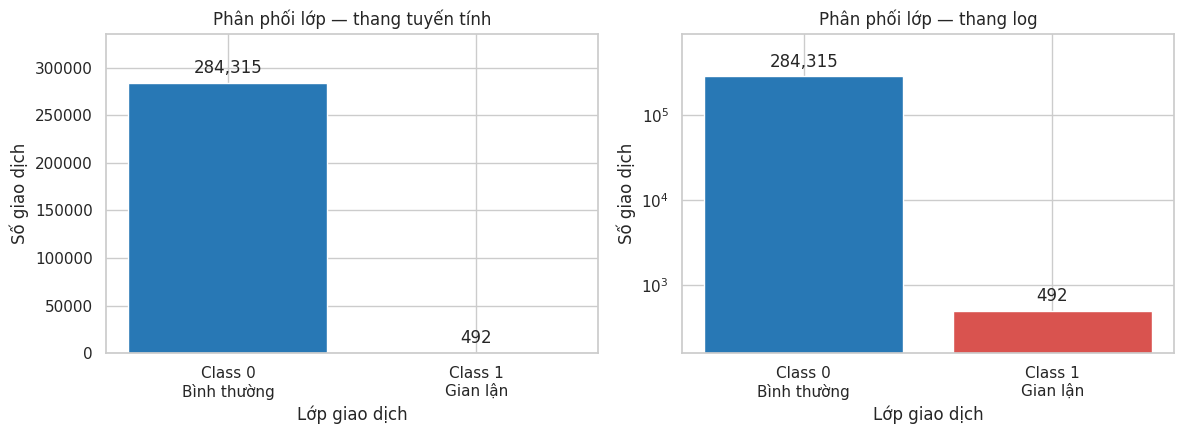

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
class_labels = ["Class 0\nBình thường", "Class 1\nGian lận"]
colors = [CLASS_PALETTE[0], CLASS_PALETTE[1]]

for ax in axes:
    bars = ax.bar(class_labels, class_counts.to_numpy(), color=colors)
    ax.set_xlabel("Lớp giao dịch")
    ax.set_ylabel("Số giao dịch")
    ax.bar_label(bars, labels=[f"{count:,}" for count in class_counts], padding=4)
    ax.margins(y=0.18)
axes[0].set_title("Phân phối lớp — thang tuyến tính")
axes[1].set_yscale("log")
axes[1].set_title("Phân phối lớp — thang log")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Phân tích Amount

In [13]:
display(df[["Amount"]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T)

,count,mean,std,min,25%,50%,75%,95%,99%,max
Amount,"284,807.0000",88.3496,250.1201,0.0000,5.6000,22.0000,77.1650,365.0000,"1,017.9700","25,691.1600"


In [14]:
display(df.groupby("Class")["Amount"].describe())
print(f"Số giao dịch có Amount = 0: {df['Amount'].eq(0).sum():,}")
print(f"Số giao dịch có Amount < 0: {df['Amount'].lt(0).sum():,}")

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,"284,315.0000",88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,"25,691.1600"
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,"2,125.8700"


Số giao dịch có Amount = 0: 1,825
Số giao dịch có Amount < 0: 0


### Phân phối Amount

`log1p` chỉ dùng để vẽ; không loại các giao dịch có số tiền lớn.

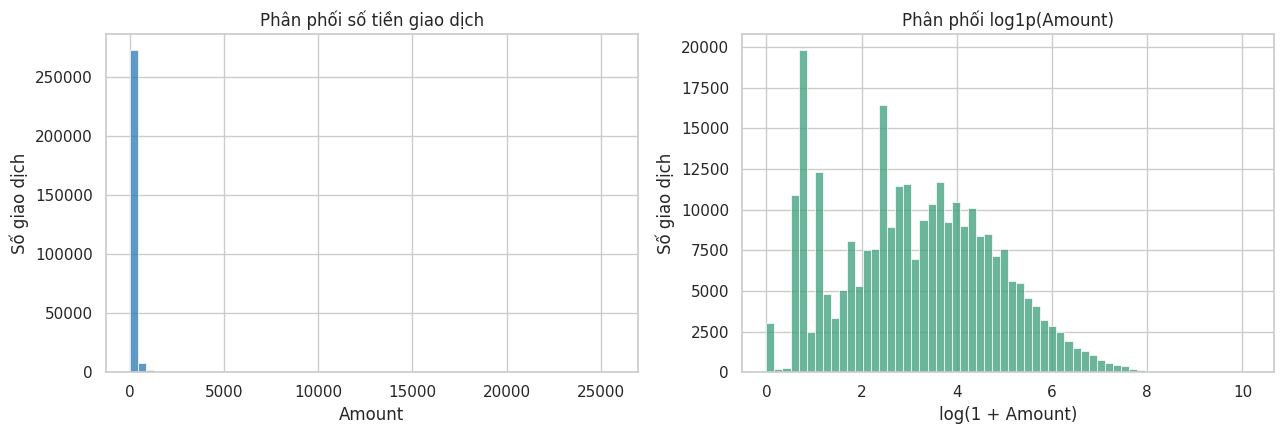

In [15]:
if df["Amount"].lt(0).any():
    raise ValueError("Amount có giá trị âm; cần kiểm tra trước khi diễn giải biểu đồ log1p.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="Amount", bins=60, color=CLASS_PALETTE[0], ax=axes[0])
axes[0].set(title="Phân phối số tiền giao dịch", xlabel="Amount", ylabel="Số giao dịch")
sns.histplot(x=np.log1p(df["Amount"]), bins=60, color="#3A9D78", ax=axes[1])
axes[1].set(title="Phân phối log1p(Amount)", xlabel="log(1 + Amount)", ylabel="Số giao dịch")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_amount_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

### Amount theo lớp

Mật độ được chuẩn hóa riêng từng lớp, không biểu diễn tỷ lệ gian lận.

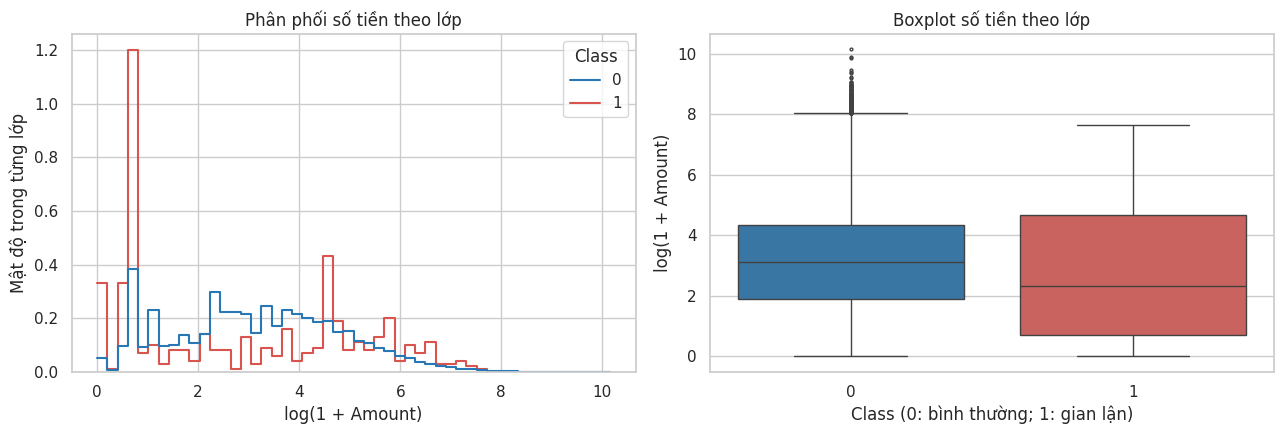

In [16]:
amount_plot_data = df[["Amount", "Class"]].assign(LogAmount=np.log1p(df["Amount"]))
amount_bins = np.histogram_bin_edges(amount_plot_data["LogAmount"].dropna(), bins=50)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(
    data=amount_plot_data, x="LogAmount", hue="Class", hue_order=[0, 1],
    bins=amount_bins, stat="density", common_norm=False,
    element="step", fill=False, palette=CLASS_PALETTE, ax=axes[0],
)
axes[0].set(title="Phân phối số tiền theo lớp", xlabel="log(1 + Amount)", ylabel="Mật độ trong từng lớp")
sns.boxplot(
    data=amount_plot_data, x="Class", y="LogAmount", hue="Class",
    order=[0, 1], hue_order=[0, 1], palette=CLASS_PALETTE,
    legend=False, fliersize=2, ax=axes[1],
)
axes[1].set(title="Boxplot số tiền theo lớp", xlabel="Class (0: bình thường; 1: gian lận)", ylabel="log(1 + Amount)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_amount_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Phân tích Time

Time là thời gian trôi qua, không phải giờ trong ngày.

In [17]:
display(df[["Time"]].describe().T)
time_min = df["Time"].min()
time_max = df["Time"].max()
print(f"Khoảng quan sát: {time_min / 3600:.2f} đến {time_max / 3600:.2f} giờ trôi qua")
print(f"Độ dài khoảng quan sát: {(time_max - time_min) / 3600:.2f} giờ")
print(f"Time có được sắp xếp tăng dần: {df['Time'].is_monotonic_increasing}")

,count,mean,std,min,25%,50%,75%,max
Time,"284,807.0000","94,813.8596","47,488.1460",0.0000,"54,201.5000","84,692.0000","139,320.5000","172,792.0000"


Khoảng quan sát: 0.00 đến 48.00 giờ trôi qua
Độ dài khoảng quan sát: 48.00 giờ
Time có được sắp xếp tăng dần: True


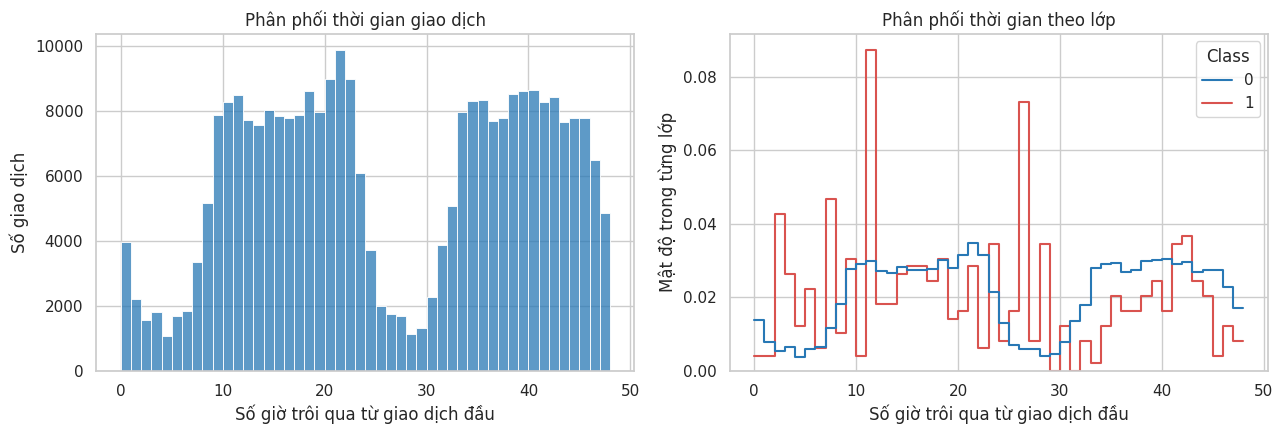

In [18]:
time_plot_data = df[["Time", "Class"]].assign(Time_hours=df["Time"] / 3600)
time_bins = np.histogram_bin_edges(time_plot_data["Time_hours"].dropna(), bins=48)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=time_plot_data, x="Time_hours", bins=time_bins, color=CLASS_PALETTE[0], ax=axes[0])
axes[0].set(title="Phân phối thời gian giao dịch", xlabel="Số giờ trôi qua từ giao dịch đầu", ylabel="Số giao dịch")
sns.histplot(
    data=time_plot_data, x="Time_hours", hue="Class", hue_order=[0, 1],
    bins=time_bins, stat="density", common_norm=False,
    element="step", fill=False, palette=CLASS_PALETTE, ax=axes[1],
)
axes[1].set(title="Phân phối thời gian theo lớp", xlabel="Số giờ trôi qua từ giao dịch đầu", ylabel="Mật độ trong từng lớp")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_time_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Phân phối một số đặc trưng V

V1, V4, V12, V14 là ví dụ cố định để quan sát, chưa phải lựa chọn đặc trưng cho mô hình.

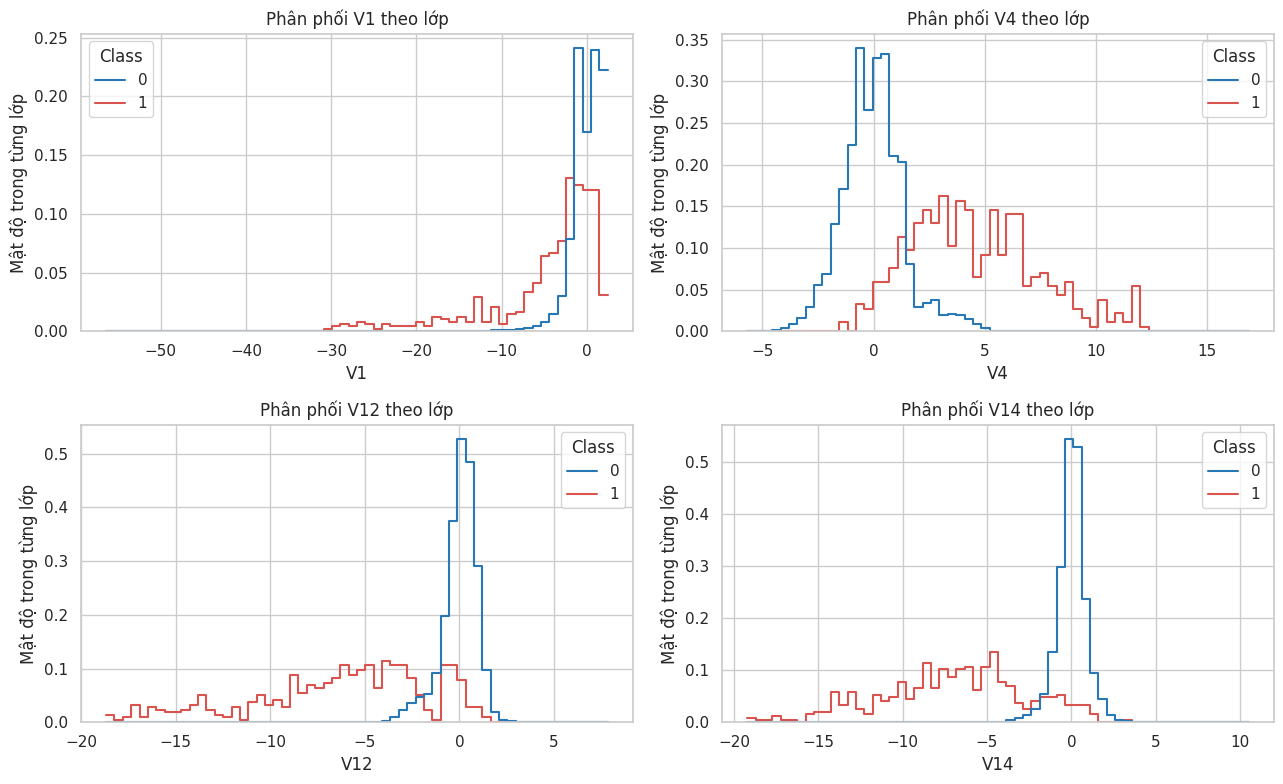

In [19]:
selected_features = ["V1", "V4", "V12", "V14"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for feature, ax in zip(selected_features, axes.flat):
    feature_bins = np.histogram_bin_edges(df[feature].dropna(), bins=60)
    sns.histplot(
        data=df, x=feature, hue="Class", hue_order=[0, 1],
        bins=feature_bins, stat="density", common_norm=False,
        element="step", fill=False, palette=CLASS_PALETTE, ax=ax,
    )
    ax.set(title=f"Phân phối {feature} theo lớp", xlabel=feature, ylabel="Mật độ trong từng lớp")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_v_features_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

### Tương quan với Class

Chỉ mô tả liên hệ tuyến tính; không chứng minh nhân quả hoặc hiệu năng dự đoán.

In [20]:
class_correlations = df.drop(columns="Class").corrwith(df["Class"]).dropna()
ranked_features = class_correlations.abs().sort_values(ascending=False).head(10).index
top_correlations = class_correlations.loc[ranked_features]
display(top_correlations.rename("Tương quan Pearson với Class").to_frame())

,Tương quan Pearson với Class
V17,-0.3265
V14,-0.3025
V12,-0.2606
V10,-0.2169
V16,-0.1965
V3,-0.1930
V7,-0.1873
V11,0.1549
V4,0.1334
V18,-0.1115


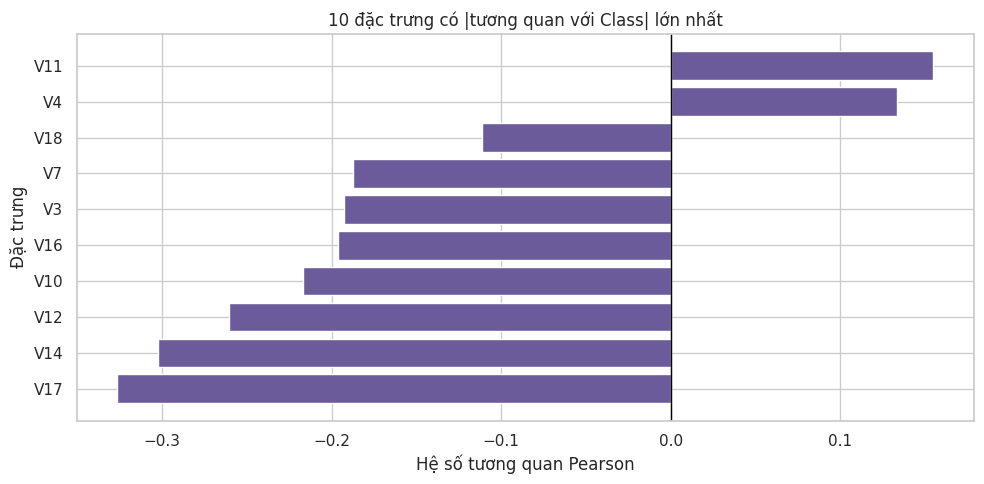

In [21]:
plot_correlations = top_correlations.sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_correlations.index, plot_correlations.values, color="#6C5B9A")
ax.axvline(0, color="black", linewidth=1)
ax.set(title="10 đặc trưng có |tương quan với Class| lớn nhất", xlabel="Hệ số tương quan Pearson", ylabel="Đặc trưng")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_class_correlations.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Tổng kết EDA

In [22]:
summary = pd.Series({
    "Số giao dịch": n_rows,
    "Số cột": n_columns,
    "Số ô thiếu": total_missing,
    "Số dòng trùng sau lần đầu": n_duplicates,
    "Giao dịch bình thường": n_normal,
    "Giao dịch gian lận": n_fraud,
    "Tỷ lệ gian lận (%)": fraud_rate,
    "Tỷ số Class 0 / Class 1": imbalance_ratio,
    "Amount trung bình": df["Amount"].mean(),
    "Amount trung vị": df["Amount"].median(),
    "Amount lớn nhất": df["Amount"].max(),
    "Amount skewness": df["Amount"].skew(),
    "Khoảng quan sát (giờ)": (time_max - time_min) / 3600,
}, name="Giá trị")
display(summary.to_frame())

,Giá trị
Số giao dịch,"284,807.0000"
Số cột,31.0000
Số ô thiếu,0.0000
Số dòng trùng sau lần đầu,"1,081.0000"
Giao dịch bình thường,"284,315.0000"
Giao dịch gian lận,492.0000
Tỷ lệ gian lận (%),0.1727
Tỷ số Class 0 / Class 1,577.8760
Amount trung bình,88.3496
Amount trung vị,22.0000


### Nhận xét cần lưu ý

- Xem xét nguồn gốc các dòng trùng trước khi chia dữ liệu; tránh bản sao xuất hiện ở nhiều tập.
- Chọn đặc trưng, fit tiền xử lý và cân bằng lớp chỉ trên tập huấn luyện; giữ tập kiểm tra độc lập.
- Đánh giá bằng precision, recall, F1, PR-AUC và confusion matrix; chưa có kết quả so sánh mô hình ở giai đoạn này.